<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 11 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude marché avec R ou Python
</h2>
</div>

<div style="background-color:RGB(46,125,50);
            border-radius:8px;
            padding:18px;
            margin-top:15px;
            color:white;">

<h3 style="margin-top:0;">Description du projet</h3>

Dans le cadre de ce projet, l'objectif est de réaliser une étude de marché afin d'identifier les pays les plus pertinents pour le développement à l'international de l'entreprise <b>La Poule qui Chante</b>. L'analyse s'appuie sur les données de la <b>FAO (Food and Agriculture Organization)

</div>

In [3]:
#Importation des librairies
import pandas as pd

import seaborn as sns

import numpy as np

from IPython.display import display

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

import squarify

import os

pd.set_option('display.float_format', '{:.2f}'.format)

In [ ]:
# Modifiez le chemin vers votre dossier contenant le notebook et les fichiers csv.
os.chdir(r".....")

# Pour vérifier
print("Nouveau répertoire :", os.getcwd())

<div style="background-color:#F5B041;
            border-left:8px solid #AF601A;
            color:#000000;
            padding:12px;
            border-radius:6px;
            margin:10px 0;">

### Import du fichier de départ

Chargement des données de la **FAO (Food and Agriculture Organization)** fournies par **Patrick**, PDG de *La Poule qui Chante*. Ces données serviront de base à l'ensemble de l'analyse de la disponibilité alimentaire.

</div>

Nota Bene : dans le cadre du scénario imaginaire proposé par le projet nous sommes en 2017, ce pourquoi nous allons autant que possible sélectionner uniquement les données de cette période dans les différents jeux de données mobilisés.

In [7]:
#Importation du fichier dispo_alimentaire.xlxs
dispo_alimentaire = pd.read_excel('Dispo_alimentaire_2017.xlsx')

In [8]:
# Affichage des premières lignes du jeu de données
display(dispo_alimentaire.head())

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.00,S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.00,S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.00,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.00,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.00,S,Données standardisées


In [9]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(dispo_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(dispo_alimentaire.shape[1]))

Le tableau comporte 176600 observation(s) ou article(s)
Le tableau comporte 14 colonne(s)


In [10]:
#Afficher les valeurs uniques de la colonne Unité
print(dispo_alimentaire['Unité'].unique())

['Milliers de tonnes' 'kg' 'Kcal/personne/jour' 'g/personne/jour']


In [11]:
#Afficher le nombre d'individus (pays)
print(len(dispo_alimentaire['Zone'].unique()))

174


<div style=" background-color: RGB(0,114,200);" >
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">1 : Import et traitement des variables PESTEL
</h2>
</div>

<div style="background-color:RGB(46,125,50);
            border-radius:8px;
            padding:18px;
            margin-top:15px;
            color:white;">

<h3 style="margin-top:0;">Variables PESTEL retenues</h3>

Les indicateurs sélectionnés permettent d'évaluer l'attractivité des marchés selon les dimensions <b>PESTEL</b> :
<ul>
<li><b>Politique :</b> stabilité du pays et niveau de protectionnisme.</li>
<li><b>Économique :</b> pouvoir d'achat (PIB/habitant) et dépendance aux importations.</li>
<li><b>Social :</b> ancrage culturel de la consommation de volaille et dynamique démographique.</li>
<li><b>Technologique :</b> qualité des infrastructures logistiques.</li>
<li><b>Environnemental :</b> exposition aux risques naturels.</li>
<li><b>Légal :</b> existence d'accords commerciaux avec l'Union européenne.</li>
</ul>

Ces variables serviront à construire un score d'attractivité des différents marchés.

</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Politique - 1 : Indice de stabilité</h3>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

L'indice de <b>Political Stability (PV)</b>, publié par la <b>Banque mondiale</b>, mesure le niveau de stabilité politique d'un pays et le risque que son gouvernement soit déstabilisé par des conflits, des actes de violence ou des événements susceptibles de perturber sa gouvernance.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cet indicateur permet d'évaluer le <b>niveau de risque</b> associé à un marché. Un pays peut présenter une forte demande potentielle, mais une instabilité politique importante peut compromettre les échanges commerciaux, perturber la logistique ou fragiliser un investissement à long terme.

<h3 style="color:white;">Sources</h3>

- <a href="https://www.worldbank.org/en/publication/worldwide-governance-indicators" target="_blank" style="color:#5DADE2;">Worldwide Governance Indicators – Banque mondiale</a>
- <a href="https://www.worldbank.org/content/dam/sites/govindicators/doc/PV-2025.pdf" target="_blank" style="color:#5DADE2;">Documentation méthodologique – Political Stability (PV)</a>

</div>

In [16]:
#Importation du fichier .xlxs
political_stability = pd.read_excel('wgi.xlsx', sheet_name = "pv")

In [17]:
display(political_stability.head(5))

,ID variable (economy code/ gov. dimension/ year),Economy (name),Economy (code),Region,Income classification,Year,Governance dimension,Number of sources,Governance estimate (approx. -2.5 to +2.5),Standard error (estimate),...,OBI mean,PIA mean,PRS mean,RSF mean,VAB mean,VDM mean,WBS mean,WCY mean,WJP mean,WMO mean
0,ADOpv1996,Andorra,ADO,NaN,NaN,1996,pv,1,1.25,0.42,...,..,..,..,..,..,..,..,..,..,1
1,AFGpv1996,Afghanistan,AFG,South Asia,Low income,1996,pv,2,-2.82,0.36,...,..,..,..,..,..,..,..,..,..,0.06
2,AGOpv1996,Angola,AGO,Sub-Saharan Africa,Lower middle income,1996,pv,4,-2.48,0.30,...,..,..,0.62,..,..,..,..,..,..,0.12
3,ALBpv1996,Albania,ALB,Europe & Central Asia,Upper middle income,1996,pv,4,-0.72,0.33,...,..,..,0.91,..,..,0.44,..,..,..,0.44
4,AREpv1996,United Arab Emirates,ARE,Middle East & North Africa,High income,1996,pv,4,1.05,0.30,...,..,..,0.80,..,..,..,..,..,..,0.94


On commence par exclure toutes les années à part 2017

In [19]:
political_stability_2017 = political_stability[political_stability['Year'] == 2017].copy()
display(political_stability_2017.head())

,ID variable (economy code/ gov. dimension/ year),Economy (name),Economy (code),Region,Income classification,Year,Governance dimension,Number of sources,Governance estimate (approx. -2.5 to +2.5),Standard error (estimate),...,OBI mean,PIA mean,PRS mean,RSF mean,VAB mean,VDM mean,WBS mean,WCY mean,WJP mean,WMO mean
3713,ABWpv2017,Aruba,ABW,Latin America & Caribbean,High income,2017,pv,3,1.21,0.30,...,..,..,..,..,..,..,..,..,..,0.89
3714,ADOpv2017,Andorra,ADO,NaN,NaN,2017,pv,2,1.33,0.36,...,..,..,..,..,..,..,..,..,..,1
3715,AFGpv2017,Afghanistan,AFG,South Asia,Low income,2017,pv,7,-2.61,0.26,...,..,..,..,..,..,0.38,..,..,0.09,0.17
3716,AGOpv2017,Angola,AGO,Sub-Saharan Africa,Lower middle income,2017,pv,11,-0.54,0.22,...,..,..,0.58,..,..,0.53,..,..,..,0.67
3717,AIApv2017,Anguilla,AIA,NaN,NaN,2017,pv,2,1.22,0.34,...,..,..,..,..,..,..,..,..,..,0.89


In [20]:
print(len(political_stability_2017['Economy (name)'].unique()))

212


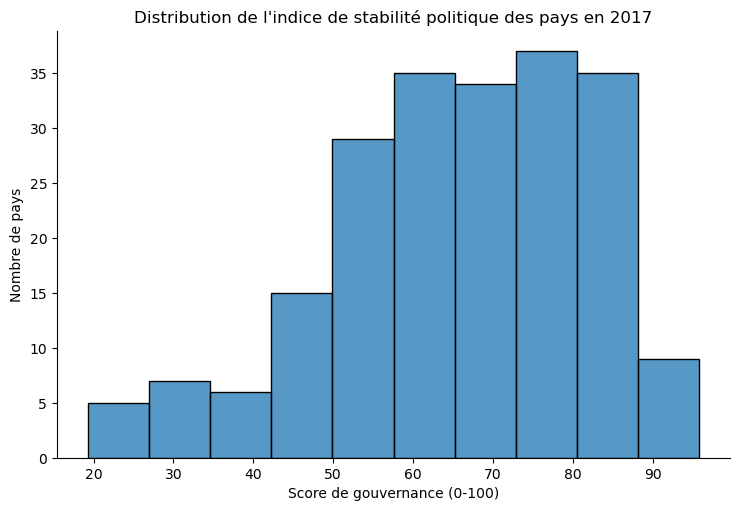

In [21]:
sns.displot(
    political_stability_2017,
    x='Governance score (0-100)',
    height=5,
    aspect=1.5
)

plt.title("Distribution de l'indice de stabilité politique des pays en 2017")
plt.xlabel("Score de gouvernance (0-100)")
plt.ylabel("Nombre de pays")

plt.show()

In [22]:
#Afficher les colonnes du dataset
political_stability_2017.columns

Index(['ID variable (economy code/ gov. dimension/ year)', 'Economy (name)',
       'Economy (code)', 'Region', 'Income classification', 'Year',
       'Governance dimension', 'Number of sources',
       'Governance estimate (approx. -2.5 to +2.5)',
       'Standard error (estimate)',
       'Lower threshold (90% conf. int. estimate)',
       'Upper threshold (90% conf. int. estimate)', 'Governance score (0-100)',
       'Standard error (gov. score)', 'Lower threshold (90% conf. int. score)',
       'Upper threshold (90% conf. int. score)', 'ADB mean', 'AFR mean',
       'ARB mean', 'ASB mean', 'ASD mean', 'BPS mean', 'BTI mean', 'CCR mean',
       'EBR mean', 'EIU mean', 'EQI mean', 'EUB mean', 'FRH mean', 'GCB mean',
       'GCS mean', 'GII mean', 'GWP mean', 'HER mean', 'HRM mean', 'HUM mean',
       'IFD mean', 'IJT mean', 'IRP mean', 'LBO mean', 'MSI mean', 'OBI mean',
       'PIA mean', 'PRS mean', 'RSF mean', 'VAB mean', 'VDM mean', 'WBS mean',
       'WCY mean', 'WJP mean', 'WM

Beaucoup de colonnes inutiles dans le fichier original. On va les exclure.

In [24]:
political_stability_2017_short = (
    political_stability_2017[
        ['Economy (name)', 'Governance score (0-100)']
    ].copy()
)
display(political_stability_2017_short.head(2))

,Economy (name),Governance score (0-100)
3713,Aruba,86.51
3714,Andorra,88.53


In [25]:
print(max(political_stability_2017_short['Governance score (0-100)']))
print(min(political_stability_2017_short['Governance score (0-100)']))

95.8370978
19.253038999999998


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Politique - 2 : Accords commerciaux</h3>
</div>

Nota Bene : Filtre qualitatif à utiliser après l'ACP

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

L'existence d'un <b>accord commercial</b> mesure le niveau de facilitation des échanges entre deux pays ou zones économiques. Cet indicateur qualitatif permet d'identifier les marchés bénéficiant de conditions commerciales favorables.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cet indicateur agit comme un <b>filtre d'accès au marché</b>. La présence d'un accord commercial peut réduire les barrières douanières, améliorer la compétitivité prix et faciliter l'exportation des produits de <b>La Poule qui Chante</b>.

<h3 style="color:white;">Typologie des accords commerciaux</h3>

<ul>
<li><b>FTA (Free Trade Agreement) :</b> suppression des droits de douane sur la majorité des biens échangés.</li>

<li><b>CU (Customs Union) :</b> zone de libre-échange avec une politique commerciale commune vis-à-vis des pays tiers.</li>

<li><b>EIA (Economic Integration Agreement) :</b> accord d'intégration économique incluant les services.</li>

<li><b>PSA (Partial Scope Agreement) :</b> réduction des droits de douane limitée à certains produits.</li>

<li><b>FTA & EIA :</b> combinaison couvrant les biens et les services.</li>

<li><b>CU & EIA :</b> union douanière étendue aux services.</li>

<li><b>PSA & EIA :</b> accord partiel incluant également un volet services.</li>
</ul>

<h3 style="color:white;">Source</h3>

- <a href="https://rtais.wto.org/UI/PublicMaintainRTAHome.aspx" target="_blank" style="color:#5DADE2;">Regional Trade Agreements Database – Organisation mondiale du commerce (OMC)</a>

</div>

In [29]:
#Importation du fichier rta.xlxs
RTA = pd.read_excel('AllRTAs.xlsx', sheet_name = 'AllRTAs')

In [30]:
display(RTA.head(5))

,RTA ID,RTA Name,Coverage,Type,Notification,Status,Date of Signature (G),Date of Signature (S),Date of Notification (G),Date of Notification (S),...,Current signatories,Original signatories,Specific Entry/Exit dates,WTO Consideration Process (G),Consideration Date (G),WTO Consideration Process (S),Consideration Date (S),End of implementation period (G),End of implementation period (S),Remarks
0,155,Australia - Gulf Cooperation Council (GCC),NaN,NaN,NaN,Early announcement-Under negotiation,NaT,NaT,NaT,NaT,...,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN
1,373,Bay of Bengal Initiative on Multi-Sectoral Tec...,NaN,NaN,NaN,Early announcement-Under negotiation,NaT,NaT,NaT,NaT,...,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN
2,160,Canada - CARICOM,NaN,NaN,NaN,Early announcement-Under negotiation,NaT,NaT,NaT,NaT,...,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN
3,161,Canada - Dominican Republic,NaN,NaN,NaN,Early announcement-Under negotiation,NaT,NaT,NaT,NaT,...,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN
4,163,Canada - El Salvador - Guatemala - Honduras - ...,NaN,NaN,NaN,Early announcement-Under negotiation,NaT,NaT,NaT,NaT,...,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaN


In [31]:
#Afficher les valeurs uniques de la colonne RTA (types d'accords)
print(RTA['Status'].unique())

['Early announcement-Under negotiation' 'Early announcement-Signed '
 'In force for at least one Party' 'In Force' 'Inactive']


Ici, on ne va conserver que les accords appliqués ('In Force')

In [33]:
RTA_in_force = RTA[RTA['Status'] == 'In Force'].copy()

In [34]:
display(RTA_in_force.head())

,RTA ID,RTA Name,Coverage,Type,Notification,Status,Date of Signature (G),Date of Signature (S),Date of Notification (G),Date of Notification (S),...,Current signatories,Original signatories,Specific Entry/Exit dates,WTO Consideration Process (G),Consideration Date (G),WTO Consideration Process (S),Consideration Date (S),End of implementation period (G),End of implementation period (S),Remarks
40,1086,African Continental Free Trade Area (AfCFTA),Goods,FTA,Enabling Clause,In Force,2018-03-21,NaT,2025-06-18,NaT,...,Algeria; Angola; Botswana; Burundi; Cameroon; ...,Algeria; Angola; Botswana; Burundi; Cameroon; ...,NaN,Awaiting data from the Parties,NaT,NaN,NaT,NaN,NaN,"Signed but not yet ratified by:\nBenin, Libya,..."
41,583,Agadir Agreement,Goods,FTA,Enabling Clause,In Force,2004-02-25,NaT,2016-02-22,NaT,...,Jordan; Morocco; Tunisia; Egypt,Jordan; Morocco; Tunisia; Egypt,NaN,Factual Presentation issued,2018-11-21,NaN,NaT,2007.00,NaN,NaN
42,127,Andean Community (CAN),Goods,CU,Enabling Clause,In Force,1987-05-12,NaT,1990-10-01,NaT,...,"Bolivia, Plurinational State of; Colombia; Ecu...","Bolivia, Plurinational State of; Colombia; Ecu...","Venezuela, Bolivarian Republic of( - 22-Apr-2011)",No report,NaT,NaN,NaT,2008.00,NaN,The original Cartagena Agreement was signed in...
43,661,Argentina - Mexico,Goods,PSA,Enabling Clause,In Force,1986-10-24,NaT,2019-07-23,NaT,...,Argentina; Mexico,Argentina; Mexico,NaN,Factual Presentation issued,2025-03-26,NaN,NaT,2014.00,NaN,Reference LAIA: AAP.CE 6.\nThis Agreement was ...
44,50,Armenia - Kazakhstan,Goods,FTA,GATT Art. XXIV,In Force,1999-09-02,NaT,2004-06-17,NaT,...,Armenia; Kazakhstan,Armenia; Kazakhstan,NaN,Factual Presentation issued,2019-09-17,NaN,NaT,2003.00,NaN,NaN


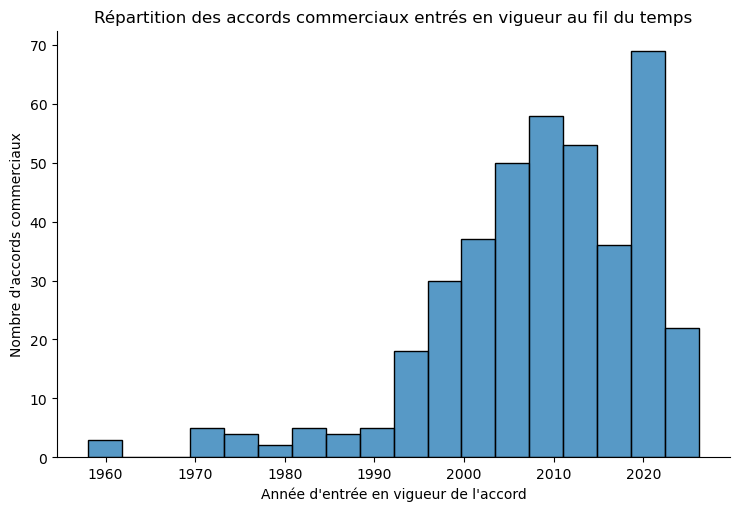

In [35]:
sns.displot(
    RTA_in_force,
    x='Date of Entry into Force (G)',
    height=5,
    aspect=1.5
)

plt.title("Répartition des accords commerciaux entrés en vigueur au fil du temps")
plt.xlabel("Année d'entrée en vigueur de l'accord")
plt.ylabel("Nombre d'accords commerciaux")

plt.show()

In [36]:
RTA_in_force_2017 = RTA_in_force[RTA_in_force['Date of Entry into Force (G)'] <= pd.to_datetime('2017-01-01')].copy()

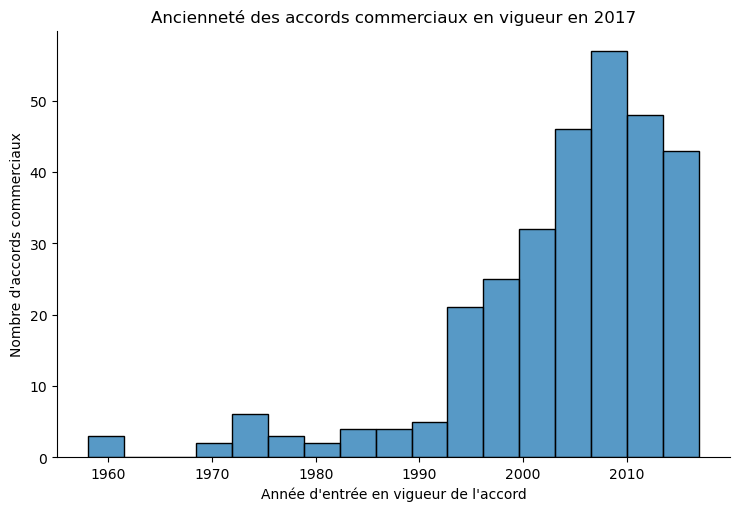

In [37]:
sns.displot(
    RTA_in_force_2017,
    x='Date of Entry into Force (G)',
    height=5,
    aspect=1.5
)

plt.title("Ancienneté des accords commerciaux en vigueur en 2017")
plt.xlabel("Année d'entrée en vigueur de l'accord")
plt.ylabel("Nombre d'accords commerciaux")

plt.show()

In [38]:
RTA_in_force_2017.to_excel(
    r"....",
    index=False
)

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Politique - 2bis : droit de douane</h3>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

Les <b>droits de douane appliqués au poulet frais ou réfrigéré</b> représentent les taxes imposées à l'importation par un pays sur ce type de produit. Cet indicateur mesure la <b>barrière tarifaire</b> à l'entrée sur un marché étranger.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cet indicateur permet d'évaluer la <b>compétitivité prix</b> d'une offre export. Un marché présentant une forte demande structurelle peut perdre en attractivité si les droits de douane réduisent la marge ou rendent le produit moins compétitif face aux producteurs locaux.

<h3 style="color:white;">Lecture business</h3>

Un niveau élevé de droits de douane constitue une <b>contrainte à l'exportation</b>, tandis qu'un tarif faible ou nul représente un avantage facilitant l'accès au marché.

<h3 style="color:white;">Source</h3>

- <a href="https://wits.worldbank.org/tariff/trains/en/country/EUN/partner/ALB/product/all" target="_blank" style="color:#5DADE2;">World Integrated Trade Solution (WITS) – Banque mondiale</a>

</div>

Nota Bene : Pour cet indicateur, malheureusement, les données disponibles pour 2017 ne sont pas assez nombreuses. Nous allons conserver les données de l'année 2022 ce qui est un choix uchronique, nous en avons conscience. 

In [42]:
#Importation du fichier tarif douanier sur le poulet.xlxs
tarif_export = pd.read_excel('tarif_france_export_poulet.xlsx', sheet_name = 'Country-TariffData')
display(tarif_export.head(5))

,Reporter,Year,Partner,Product,MFNRate,AppliedTariff,TotalTariffLines,IsTraded
0,Afghanistan,2018,France,"020711 - Not cut in pieces, fresh or chilled",5.00,5.00,1,No
1,Angola,2022,France,"020711 - Not cut in pieces, fresh or chilled",10.00,10.00,1,Yes
2,Anguila,2021,France,"020711 - Not cut in pieces, fresh or chilled",0.00,0.00,1,No
3,Albania,2022,France,"020711 - Not cut in pieces, fresh or chilled",10.00,10.00,3,No
4,United Arab Emirates,2022,France,"020711 - Not cut in pieces, fresh or chilled",5.00,5.00,1,Yes


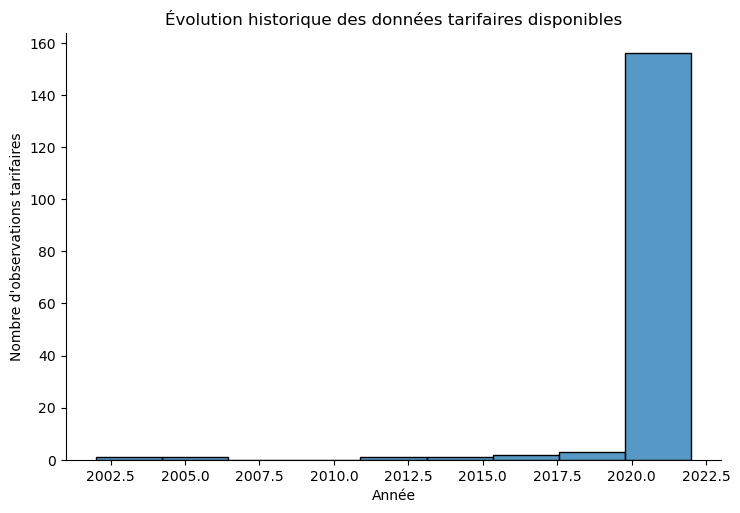

In [43]:
sns.displot(
    tarif_export,
    x='Year',
    height=5,
    aspect=1.5
)

plt.title("Évolution historique des données tarifaires disponibles")
plt.xlabel("Année")
plt.ylabel("Nombre d'observations tarifaires")

plt.show()

In [44]:
#Conserver 2022
tarif_export_2022 = tarif_export[tarif_export['Year'] == 2022].copy()

In [45]:
print(len(tarif_export_2022['Year']))

125


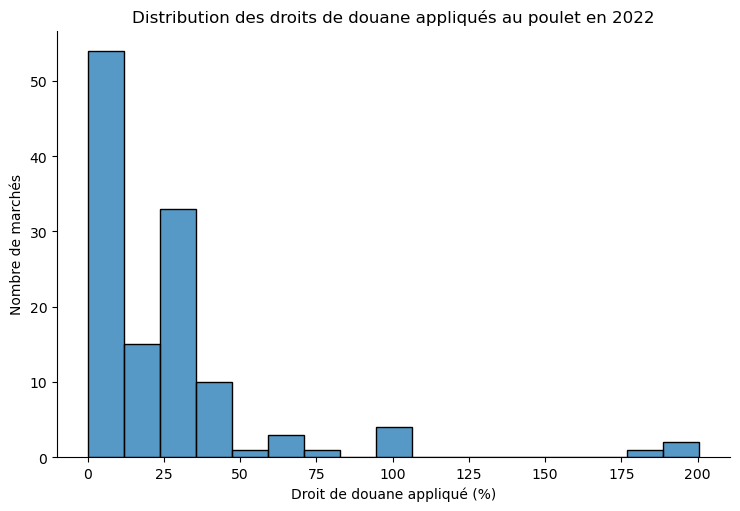

In [46]:
sns.displot(
    tarif_export_2022,
    x='AppliedTariff',
    height=5,
    aspect=1.5
)

plt.title("Distribution des droits de douane appliqués au poulet en 2022")
plt.xlabel("Droit de douane appliqué (%)")
plt.ylabel("Nombre de marchés")

plt.show()

In [47]:
tarif_export_2022_short = tarif_export_2022[
    ['Reporter', 'AppliedTariff']
].copy()

display(tarif_export_2022_short.head(2))

,Reporter,AppliedTariff
1,Angola,10.00
3,Albania,10.00


In [48]:
print(max(tarif_export_2022_short['AppliedTariff']))
print(min(tarif_export_2022_short['AppliedTariff']))

200.54080200195312
0.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.3 - Economie - 1 : PIB par tête</h3>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

Le <b>PIB par habitant (prix courants, dollars US)</b> mesure la richesse économique moyenne produite par habitant dans un pays. Cet indicateur permet d'approcher le <b>niveau de pouvoir d'achat</b> d'un marché potentiel.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cette variable permet d'évaluer la <b>capacité d'un marché à absorber des produits importés</b>. Un PIB par tête élevé peut traduire une population disposant d'un pouvoir d'achat suffisant pour accéder à des produits alimentaires à plus forte valeur ajoutée.

<h3 style="color:white;">Lecture business</h3>

Un niveau élevé de PIB par habitant représente une <b>opportunité commerciale</b> en indiquant un potentiel de consommation plus important. 
<h3 style="color:white;">Source</h3>

- <a href="https://www.imf.org/en/publications/weo/weo-database/2017/october" target="_blank" style="color:#5DADE2;">World Economic Outlook Database – Fonds Monétaire International (FMI)</a>

</div>

In [51]:
#Importation du fichier tarif douanier sur le poulet
gdp_per_capita = pd.read_excel('GDP_per_capita_2000_2017.xlsx')
display(gdp_per_capita.head(5))

,WEO Country Code,WEO Subject Code,Country,Subject Descriptor,Units,Scale,Country/Series-specific Notes,2000,2001,2002,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Estimates Start After
0,512,NGDPDPC,Afghanistan,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",NaN,NaN,196.68,...,435.47,539.67,614.66,680.43,660.22,659.10,627.34,582.46,572.16,2013.00
1,914,NGDPDPC,Albania,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",1127.64,1283.57,1425.12,...,4130.93,4098.12,4438.93,4248.81,4415.66,4584.91,3935.67,4125.70,4520.27,2011.00
2,612,NGDPDPC,Algeria,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",1794.69,1768.58,1806.86,...,3886.06,4480.72,5453.89,5574.51,5477.06,5466.33,4150.69,3901.81,4225.00,2016.00
3,614,NGDPDPC,Angola,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",535.47,508.86,690.92,...,3393.55,3599.27,4411.57,4744.88,4988.92,4915.92,3876.20,3484.53,4401.43,2015.00
4,311,NGDPDPC,Antigua and Barbuda,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",10981.38,10414.64,10482.37,...,14616.95,13613.47,13346.77,14006.82,13646.31,14488.09,15282.67,16175.59,16826.19,2011.00


In [52]:
#Conserver 2017
gdp_per_capita_2017 = gdp_per_capita[
    ['Country', 'Subject Descriptor', 2017]
].copy()
display(gdp_per_capita_2017.head())

,Country,Subject Descriptor,2017
0,Afghanistan,"Gross domestic product per capita, current prices",572.16
1,Albania,"Gross domestic product per capita, current prices",4520.27
2,Algeria,"Gross domestic product per capita, current prices",4225.00
3,Angola,"Gross domestic product per capita, current prices",4401.43
4,Antigua and Barbuda,"Gross domestic product per capita, current prices",16826.19


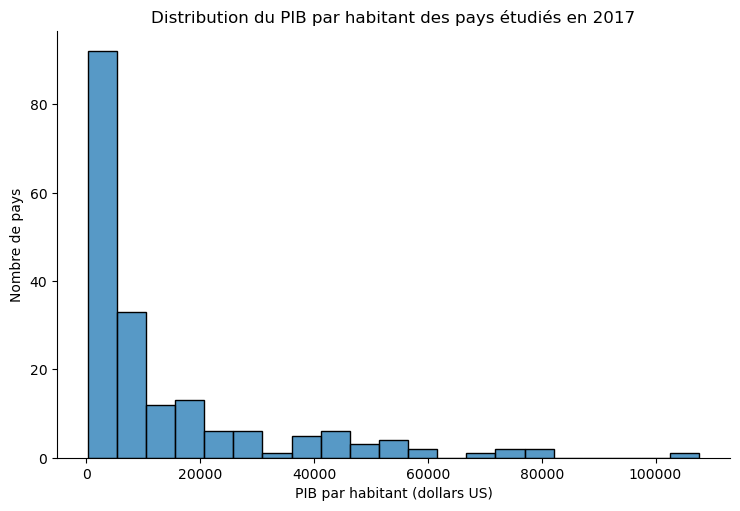

In [53]:
sns.displot(
    gdp_per_capita_2017,
    x=2017,
    height=5,
    aspect=1.5
)

plt.title("Distribution du PIB par habitant des pays étudiés en 2017")
plt.xlabel("PIB par habitant (dollars US)")
plt.ylabel("Nombre de pays")

plt.show()

In [54]:
print(max(gdp_per_capita_2017[2017]))
print(min(gdp_per_capita_2017[2017]))

107708.217
221.908


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.4 - Economie - 2 : Dépendance aux importations de volailles</h3>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

Le ratio <b>part des importations / disponibilité alimentaire</b>, calculé à partir des données de la <b>FAO</b>, mesure la dépendance d'un pays aux importations pour couvrir ses besoins en volaille.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cet indicateur permet d'identifier les marchés présentant un <b>besoin structurel d'approvisionnement extérieur</b>. Un pays fortement dépendant des importations peut représenter une opportunité pour un acteur exportateur capable de répondre à cette demande.

<h3 style="color:white;">Lecture business</h3>

Une dépendance élevée aux importations constitue une <b>opportunité commerciale</b>, car elle traduit un déficit de production locale.

<h3 style="color:white;">Source</h3>

- Fichier <b>FAO</b> précédemment chargé dans l'analyse

</div>

In [57]:
display(dispo_alimentaire.head(5))

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.00,S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.00,S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.00,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.00,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.00,S,Données standardisées


In [58]:
#Conserver uniquement les données concernant la volaille
dispo_alimentaire_volaille_2017 = dispo_alimentaire[dispo_alimentaire['Produit'] == 'Viande de Volailles'].copy()
display(dispo_alimentaire_volaille_2017.head(5))

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
651,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2734,Viande de Volailles,2017,2017,Milliers de tonnes,28.00,S,Données standardisées
652,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2734,Viande de Volailles,2017,2017,Milliers de tonnes,29.00,S,Données standardisées
653,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2734,Viande de Volailles,2017,2017,Milliers de tonnes,0.00,S,Données standardisées
654,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2734,Viande de Volailles,2017,2017,Milliers de tonnes,57.00,S,Données standardisées
655,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5123,Pertes,2734,Viande de Volailles,2017,2017,Milliers de tonnes,2.00,S,Données standardisées


In [59]:
# Pour chaque pays, calculer le ratio volaille consommée sur volaille importée et le stocker dans le df : part_importation_volaille_2017
part_importations_volaille_2017 = pd.DataFrame(columns=['Zone', 'Part_import_volaille'])

liste_pays = []



i = 0

for index, rows in dispo_alimentaire_volaille_2017.iterrows():
    if rows['Zone'] not in liste_pays:
        pay = rows['Zone']
        liste_pays.append(pay)
        part_importations_volaille_2017.loc[i, 'Zone'] = pay
        dividende = 0
        diviseur = 0
        to_divide = True
    if rows['Zone'] in liste_pays:
        if rows['Élément'] == 'Nourriture':
            diviseur = rows['Valeur']
        if rows['Élément'] == 'Importations - Quantité':
            dividende = rows['Valeur']
    if dividende != 0 and diviseur != 0 and to_divide == True:
        resultat = (dividende / diviseur) * 100
        part_importations_volaille_2017.loc[i, 'Part_import_volaille'] = resultat
        i += 1
        to_divide= False

display(part_importations_volaille_2017.head(5))

,Zone,Part_import_volaille
0,Afghanistan,52.73
1,Afrique du Sud,25.26
2,Albanie,80.85
3,Algérie,0.76
4,Allemagne,52.33


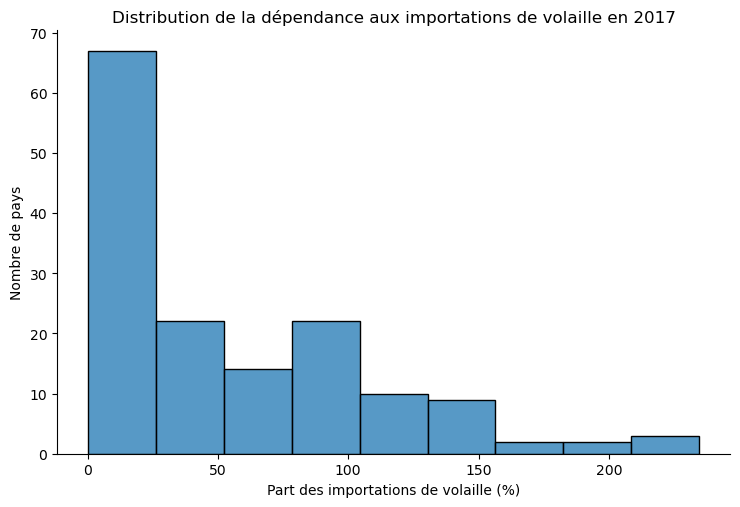

In [60]:
sns.displot(
    part_importations_volaille_2017,
    x='Part_import_volaille',
    height=5,
    aspect=1.5
)

plt.title("Distribution de la dépendance aux importations de volaille en 2017")
plt.xlabel("Part des importations de volaille (%)")
plt.ylabel("Nombre de pays")

plt.show()

In [61]:
print(max(part_importations_volaille_2017['Part_import_volaille']))
print(min(part_importations_volaille_2017['Part_import_volaille']))

234.72222222222223
0.030054097375275493


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.5 - Socioculturel - 1 : Indice de demande culturelle</h3>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

La <b>part de la volaille dans les protéines animales disponibles</b>, issue des données <b>FAO</b>, mesure l'importance relative de la consommation de volaille dans les habitudes alimentaires d'un pays.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cet indicateur permet d'évaluer l'<b>ancrage culturel du produit</b> et son potentiel d'acceptation par les consommateurs locaux. Une forte place de la volaille dans les apports en protéines animales peut traduire une préférence alimentaire déjà établie.

<h3 style="color:white;">Lecture business</h3>

La combinaison entre une <b>forte consommation de volaille</b> et une <b>faible disponibilité locale</b> peut révéler un marché présentant une demande structurelle, favorable à un acteur exportateur.

<h3 style="color:white;">Source</h3>

- Fichier <b>FAO</b> précédemment chargé dans l'analyse

</div>

In [64]:
display(dispo_alimentaire.head(5))

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.00,S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.00,S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.00,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.00,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.00,S,Données standardisées


In [65]:
# Pour chaque pays, calculer la part de protéines de volaille dans les protéines animales consommées et le stocker dans le df : score_culturel_volaille
score_culturel_volaille = pd.DataFrame(columns=['Zone', 
                                                'score_culturel', 
                                                'Disponibilité alimentaire (Kcal/personne/jour)', 
                                                'Prot_animale (Kcal/personne/jour)',
                                                'Disponibilité intérieure',
                                               'Importations - Quantité',
                                               'Exportations - Quantité'])

liste_pays = []

liste_prot_animale = [
    'Abats Comestible',
    'Graisses Animales Crue',
    'Oeufs',
    'Poissons Eau Douce',
    'Viande de Bovins',
    'Viande de Suides',
    "Viande d'Ovins/Caprins",
    'Viande, Autre',
    'Poissons Pelagiques',
    'Poissons Marins, Autres',
    'Viande de Volailles'
]

i = 0

for index, rows in dispo_alimentaire.iterrows():
    forward = index + 1
    if rows['Zone'] not in liste_pays:
        pay = rows['Zone']
        liste_pays.append(pay)
        score_culturel_volaille.loc[i, 'Zone'] = pay
        kcal_volaille = 0
        kcal_prot_animal = 0
        volaille_export = 0
        volaille_import = 0
        volaille_dispo = 0
        to_divide = True
    if rows['Zone'] in liste_pays:
        if rows['Produit'] == 'Viande de Volailles':
            if rows['Élément'] == 'Disponibilité alimentaire (Kcal/personne/jour)':
               kcal_volaille = rows['Valeur']
            if rows['Élément'] == 'Disponibilité intérieure':
               volaille_dispo = rows['Valeur']
            if rows['Élément'] == 'Importations - Quantité':
               volaille_import = rows['Valeur']
            if rows['Élément'] == 'Exportations - Quantité':
               volaille_export = rows['Valeur']
        if rows['Produit'] in liste_prot_animale and rows['Élément'] == 'Disponibilité alimentaire (Kcal/personne/jour)':
            kcal_prot_animal += rows['Valeur']
        
    if forward not in dispo_alimentaire.index or rows['Zone'] != dispo_alimentaire.loc[forward, 'Zone'] and kcal_prot_animal != 0 and volaille_dispo != 0:
        resultat = ((kcal_volaille / kcal_prot_animal) * 100) 
        score_culturel_volaille.loc[i, 'score_culturel'] = resultat
        score_culturel_volaille.loc[i, 'Disponibilité alimentaire (Kcal/personne/jour)'] =  kcal_volaille
        score_culturel_volaille.loc[i, 'Disponibilité intérieure'] = volaille_dispo
        score_culturel_volaille.loc[i, 'Prot_animale (Kcal/personne/jour)'] = kcal_prot_animal
        score_culturel_volaille.loc[i, 'Importations - Quantité'] = volaille_import
        score_culturel_volaille.loc[i, 'Exportations - Quantité'] = volaille_export
        
        i += 1

score_culturel_volaille.head(10)

,Zone,score_culturel,Disponibilité alimentaire (Kcal/personne/jour),Prot_animale (Kcal/personne/jour),Disponibilité intérieure,Importations - Quantité,Exportations - Quantité
0,Afghanistan,7.14,5.00,70.00,57.00,29.00,0
1,Afrique du Sud,39.29,143.00,364.00,2118.00,514.00,63.00
2,Albanie,22.43,85.00,379.00,47.00,38.00,0.00
3,Algérie,17.19,22.00,128.00,277.00,2.00,0.00
4,Allemagne,12.28,71.00,578.00,1739.00,842.00,646.00
5,Angola,19.66,35.00,178.00,319.00,277.00,0.00
6,Antigua-et-Barbuda,50.32,233.00,463.00,7.00,7.00,0.00
7,Arabie saoudite,55.72,151.00,271.00,1435.00,722.00,10.00
8,Argentine,24.50,182.00,743.00,1962.00,8.00,207.00
9,Arménie,13.08,54.00,413.00,47.00,35.00,0.00


In [66]:
score_culturel_volaille['score_culturel'] = pd.to_numeric(
    score_culturel_volaille['score_culturel']
)

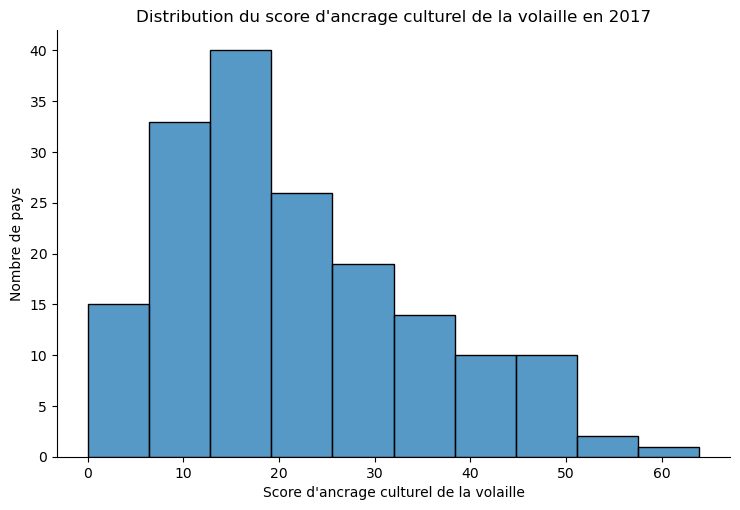

In [67]:
sns.displot(
    score_culturel_volaille,
    x='score_culturel',
    height=5,
    aspect=1.5
)

plt.title("Distribution du score d'ancrage culturel de la volaille en 2017")
plt.xlabel("Score d'ancrage culturel de la volaille")
plt.ylabel("Nombre de pays")

plt.show()

In [68]:
# Visualiser les pays avec les 20 meilleurs scores
score_culturel_volaille = score_culturel_volaille.sort_values(
    by='score_culturel',
    ascending=False)
display(score_culturel_volaille.head(20))

,Zone,score_culturel,Disponibilité alimentaire (Kcal/personne/jour),Prot_animale (Kcal/personne/jour),Disponibilité intérieure,Importations - Quantité,Exportations - Quantité
67,Guyana,63.95,165.00,258.00,32.00,0.00,0.00
7,Arabie saoudite,55.72,151.00,271.00,1435.00,722.00,10.00
139,Saint-Vincent-et-les Grenadines,54.12,243.00,449.00,8.00,9.00,0
6,Antigua-et-Barbuda,50.32,233.00,463.00,7.00,7.00,0.00
80,Jamaïque,50.00,178.00,356.00,152.00,31.00,1.00
69,Honduras,49.73,93.00,187.00,205.00,12.00,1.00
63,Grenade,49.36,192.00,389.00,8.00,7.00,0
111,Nicaragua,48.69,93.00,191.00,138.00,6.00,0.00
102,Maurice,47.58,128.00,269.00,49.00,2.00,0.00
74,Iran (République islamique d'),47.29,96.00,203.00,2220.00,6.00,45.00


In [69]:
# Réduire le df
score_culturel_volaille_short = score_culturel_volaille [['Zone', 'score_culturel']]

In [70]:
print(max(score_culturel_volaille_short['score_culturel']))
print(min(score_culturel_volaille_short['score_culturel']))

63.95348837209303
0.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.6 - Socioculturel - 2 : Croissance démongraphique</h3>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

Le <b>taux de croissance démographique</b> mesure l'évolution annuelle de la population d'un pays. Cet indicateur, fourni par la <b>Banque mondiale</b>, permet d'évaluer la dynamique démographique d'un marché potentiel.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cette variable permet d'identifier les marchés présentant un <b>potentiel de croissance de la demande</b>. Une population en augmentation peut représenter une opportunité à long terme pour un acteur exportateur, notamment sur les produits alimentaires.

<h3 style="color:white;">Lecture business</h3>

Une croissance démographique positive constitue une <b>opportunité commerciale</b>, car elle peut soutenir l'élargissement de la base de consommateurs. 

<h3 style="color:white;">Source</h3>

- <a href="https://data.worldbank.org/indicator/sp.pop.grow" target="_blank" style="color:#5DADE2;">Population growth (annual %) – Banque mondiale</a>

</div>

In [73]:
Grow_rate = pd.read_excel('Grow_rate_year_country.xlsx', sheet_name = 'Data')

In [74]:
display(Grow_rate.head(5))

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
0,Aruba,ABW,Population growth (annual %),SP.POP.GROW,NaN,1.19,1.33,1.20,1.08,0.99,...,0.76,0.68,0.23,0.74,1.47,1.49,1.07,1.02,0.76,0.01
1,Africa Eastern and Southern,AFE,Population growth (annual %),SP.POP.GROW,NaN,2.62,2.69,2.71,2.77,2.81,...,2.72,2.74,2.73,2.68,2.69,2.75,2.70,2.70,2.64,2.64
2,Afghanistan,AFG,Population growth (annual %),SP.POP.GROW,NaN,1.96,2.04,2.11,2.16,2.23,...,2.19,3.65,2.93,3.69,4.05,3.42,3.63,3.12,2.54,2.81
3,Africa Western and Central,AFW,Population growth (annual %),SP.POP.GROW,NaN,2.10,2.13,2.17,2.18,2.22,...,2.83,2.79,2.79,2.82,2.78,2.73,2.73,2.70,2.67,2.63
4,Angola,AGO,Population growth (annual %),SP.POP.GROW,NaN,1.33,0.99,1.00,1.03,1.05,...,3.78,3.80,3.85,3.89,3.88,3.85,3.73,3.61,3.58,3.54


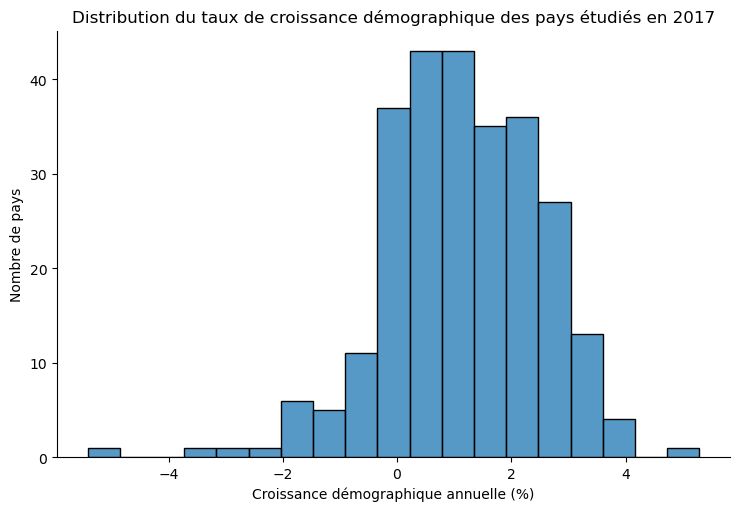

In [75]:
sns.displot(
    Grow_rate,
    x="2017",
    height=5,
    aspect=1.5
)

plt.title("Distribution du taux de croissance démographique des pays étudiés en 2017")
plt.xlabel("Croissance démographique annuelle (%)")
plt.ylabel("Nombre de pays")

plt.show()

In [76]:
# Conserver uniquement 2017
Grow_rate_short = Grow_rate[['Country Name', '2017']].copy()

In [77]:
print(max(Grow_rate_short["2017"]))
print(min(Grow_rate_short["2017"]))

5.29314527321994
-5.41590990485178


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.7 - Environnemental - 1 : Indice de vulnérabilité</h3>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

L'indice de <b>risque environnemental</b>, issu de l'outil <b>INFORM Risk Index</b>, mesure l'exposition d'un pays aux risques liés aux catastrophes naturelles et sa capacité à y faire face. Il prend en compte notamment l'exposition aux aléas, la vulnérabilité des populations et les capacités de réponse.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cet indicateur permet d'évaluer la <b>résilience d'un marché</b> face aux événements environnementaux susceptibles de perturber l'activité économique, les infrastructures ou les chaînes d'approvisionnement.

<h3 style="color:white;">Lecture business</h3>

Un niveau élevé de risque environnemental constitue une <b>contrainte pour un développement export durable</b>, car il peut augmenter l'incertitude opérationnelle et affecter la continuité des échanges commerciaux.

<h3 style="color:white;">Source</h3>

- <a href="https://drmkc.jrc.ec.europa.eu/inform-index/INFORM-Risk/Results-and-data#inline-nav-2" target="_blank" style="color:#5DADE2;">INFORM Risk Index – Joint Research Centre (Commission européenne)</a>

</div>

In [80]:
vulnerability_index = pd.read_excel('Vulnerability_index.xlsx', sheet_name = 'INFORM2026Trend')
display(vulnerability_index.head(5))

,Iso3,IndicatorId,IndicatorName,IndicatorScore,SurveyYear,Indicator Type,INFORMYear,Data reference year
0,KHM,AFF_DR,People affected by drought (absolute) - raw,258571.43,2016,Core Indicators,2017,2016
1,KIR,AFF_DR,People affected by drought (absolute) - raw,2400.00,2016,Core Indicators,2017,2016
2,KNA,AFF_DR,People affected by drought (absolute) - raw,0.00,2015,Core Indicators,2017,2016
3,KOR,AFF_DR,People affected by drought (absolute) - raw,0.00,2016,Core Indicators,2017,2016
4,KWT,AFF_DR,People affected by drought (absolute) - raw,0.00,2015,Core Indicators,2017,2016


In [81]:
# Sélectionne dans le df les données qui correspondent à l'indice de vulnérabilité et à l'année 2017 tout en réduisant les colonnes
vulnerability_index_2017 = (
    vulnerability_index
    .query("IndicatorName == 'Vulnerability Index' and INFORMYear == 2017")
    [['Iso3', 'IndicatorName', 'IndicatorScore', 'INFORMYear']]
)

In [82]:
display(vulnerability_index_2017.head(5))

,Iso3,IndicatorName,IndicatorScore,INFORMYear
306954,AFG,Vulnerability Index,7.70,2017
306955,AGO,Vulnerability Index,5.10,2017
306956,ALB,Vulnerability Index,2.50,2017
306957,ARE,Vulnerability Index,0.90,2017
306958,ARG,Vulnerability Index,1.60,2017


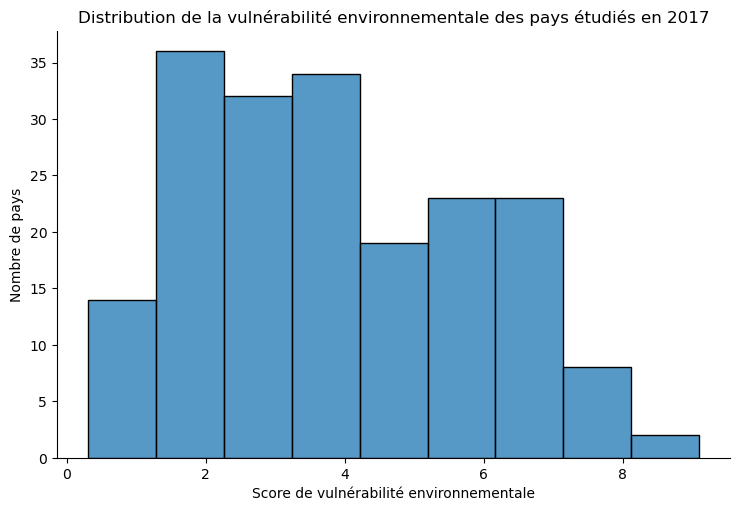

In [83]:
sns.displot(
    vulnerability_index_2017,
    x='IndicatorScore',
    height=5,
    aspect=1.5
)

plt.title("Distribution de la vulnérabilité environnementale des pays étudiés en 2017")
plt.xlabel("Score de vulnérabilité environnementale")
plt.ylabel("Nombre de pays")

plt.show()

In [84]:
vulnerability_index_2017_short = vulnerability_index_2017[['Iso3', 'IndicatorScore']]

In [85]:
display(vulnerability_index_2017_short.head(2))

,Iso3,IndicatorScore
306954,AFG,7.70
306955,AGO,5.10


In [86]:
print(max(vulnerability_index_2017_short['IndicatorScore']))
print(min(vulnerability_index_2017_short['IndicatorScore']))

9.1
0.3


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.8 - Technologique - 1 : Faisabilité logistique</h3>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Définition</h3>

L'<b>indice de performance logistique (LPI)</b>, publié par la <b>Banque mondiale</b>, mesure la capacité d'un pays à organiser efficacement le transport et la circulation des marchandises. Il prend notamment en compte la qualité des infrastructures, la fiabilité des services logistiques et la facilité des échanges internationaux.

<h3 style="color:white;">Intérêt pour l'étude</h3>

Cet indicateur permet d'évaluer la <b>faisabilité opérationnelle d'une implantation export</b>. Un marché peut présenter une forte demande, mais des infrastructures logistiques insuffisantes peuvent limiter la capacité à approvisionner efficacement les consommateurs.

<h3 style="color:white;">Lecture business</h3>

Un indice logistique élevé représente une <b>opportunité facilitant l'accès au marché</b>, tandis qu'un score faible constitue une <b>contrainte opérationnelle</b> pouvant augmenter les coûts et les risques liés à la distribution.

<h3 style="color:white;">Source</h3>

- <a href="https://donnees.banquemondiale.org/indicateur/LP.LPI.OVRL.XQ" target="_blank" style="color:#5DADE2;">Logistics Performance Index (LPI) – Banque mondiale</a>

</div>

Nota Bene : L'année 2017 n'étant pas remplie, nous avons conservé 2016

In [90]:
faisabilite_logistique = pd.read_excel('Indice_perf_log_country.xlsx', sheet_name = 'Data')
display(faisabilite_logistique.head(5))

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,Indice de performance logistique : performance...,LP.LPI.OVRL.XQ,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,AFE,Indice de performance logistique : performance...,LP.LPI.OVRL.XQ,NaN,NaN,NaN,NaN,NaN,NaN,...,2.58,NaN,2.49,NaN,NaN,NaN,2.62,NaN,NaN,NaN
2,Afghanistan,AFG,Indice de performance logistique : performance...,LP.LPI.OVRL.XQ,NaN,NaN,NaN,NaN,NaN,NaN,...,2.14,NaN,1.95,NaN,NaN,NaN,1.90,NaN,NaN,NaN
3,NaN,AFW,Indice de performance logistique : performance...,LP.LPI.OVRL.XQ,NaN,NaN,NaN,NaN,NaN,NaN,...,2.35,NaN,2.41,NaN,NaN,NaN,2.47,NaN,NaN,NaN
4,Angola,AGO,Indice de performance logistique : performance...,LP.LPI.OVRL.XQ,NaN,NaN,NaN,NaN,NaN,NaN,...,2.24,NaN,2.05,NaN,NaN,NaN,2.10,NaN,NaN,NaN


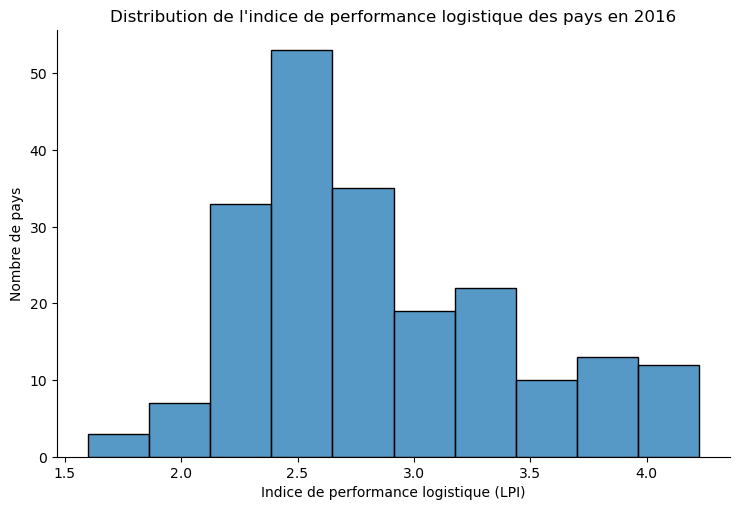

In [91]:
sns.displot(
    faisabilite_logistique,
    x='2016',
    height=5,
    aspect=1.5
)

plt.title("Distribution de l'indice de performance logistique des pays en 2016")
plt.xlabel("Indice de performance logistique (LPI)")
plt.ylabel("Nombre de pays")

plt.show()

In [92]:
faisabilite_logistique_2016 = faisabilite_logistique[
    ['Country Name', 'Country Code', 'Indicator Name', '2016']
].copy()

In [93]:
faisabilite_logistique_2016 = faisabilite_logistique_2016.rename(
    columns={'2016': 'indice_logistique'}
)

In [94]:
display(faisabilite_logistique_2016.head(5))

,Country Name,Country Code,Indicator Name,indice_logistique
0,Aruba,ABW,Indice de performance logistique : performance...,NaN
1,NaN,AFE,Indice de performance logistique : performance...,2.58
2,Afghanistan,AFG,Indice de performance logistique : performance...,2.14
3,NaN,AFW,Indice de performance logistique : performance...,2.35
4,Angola,AGO,Indice de performance logistique : performance...,2.24


In [95]:
faisabilite_logistique_2016_short = faisabilite_logistique_2016[['Country Name', 'indice_logistique']]

In [96]:
display(faisabilite_logistique_2016_short.head(2))

,Country Name,indice_logistique
0,Aruba,NaN
1,NaN,2.58


In [97]:
print(faisabilite_logistique_2016_short['indice_logistique'].max())
print(faisabilite_logistique_2016_short['indice_logistique'].min())

4.225967
1.598322


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Jointure</h2>
</div>

<div style="background-color:#343A40;
            border-left:5px solid RGB(0,150,250);
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">🔗 Stratégie de jointure</h3>

Afin de limiter les pertes d'information, les différents jeux de données seront fusionnés en utilisant systématiquement le <b>DataFrame le plus volumineux comme table de gauche</b> lors des opérations de <code>merge()</code>. Cette approche permet de conserver le maximum d'observations tout au long de la construction de la base finale.

</div>

In [100]:
display(tarif_export_2022_short.columns)

Index(['Reporter', 'AppliedTariff'], dtype='object')

In [101]:
print(len(tarif_export_2022_short))

125


In [102]:
display(political_stability_2017_short.columns)

Index(['Economy (name)', 'Governance score (0-100)'], dtype='object')

In [103]:
print(len(political_stability_2017_short))

212


In [104]:
final_df = political_stability_2017_short.merge(
    tarif_export_2022_short,
    left_on='Economy (name)',
    right_on='Reporter',
    how='left'  # conserve toutes les lignes de political_stability_2017_short
)

In [105]:
display(final_df.head(2))

,Economy (name),Governance score (0-100),Reporter,AppliedTariff
0,Aruba,86.51,NaN,NaN
1,Andorra,88.53,NaN,NaN


In [106]:
display(final_df['AppliedTariff'].isna().sum())

99

In [107]:
display(gdp_per_capita_2017.columns)

Index(['Country', 'Subject Descriptor', 2017], dtype='object')

In [108]:
print(len(gdp_per_capita_2017))

194


In [109]:
final_df = final_df.merge(
    gdp_per_capita_2017,
    left_on='Economy (name)',
    right_on='Country',
    how='left'  # final_df
)

In [110]:
display(final_df.head(2))

,Economy (name),Governance score (0-100),Reporter,AppliedTariff,Country,Subject Descriptor,2017
0,Aruba,86.51,NaN,NaN,NaN,NaN,NaN
1,Andorra,88.53,NaN,NaN,NaN,NaN,NaN


In [111]:
# Renomme la colonne 2017 en GDP_per_capita
final_df = final_df.rename(columns={
    2017: 'GDP_per_capita'
})

In [112]:
display(part_importations_volaille_2017.columns)

Index(['Zone', 'Part_import_volaille'], dtype='object')

In [113]:
print(len(part_importations_volaille_2017))

151


In [114]:
display(Grow_rate_short.columns)

Index(['Country Name', '2017'], dtype='object')

In [115]:
# Renomme la colonne 2017 en Croissance démongraphique
Grow_rate_short = Grow_rate_short.rename(columns={
    '2017': 'Croissance_demographique'
})

In [116]:
display(Grow_rate_short.columns)

Index(['Country Name', 'Croissance_demographique'], dtype='object')

In [117]:
print(len(Grow_rate_short))

266


In [118]:
final_df = Grow_rate_short.merge(
    final_df,
    left_on='Country Name',
    right_on='Economy (name)',
    how='left'  # conserve toutes les lignes de final_df
)

In [119]:
display(final_df.head(2))

,Country Name,Croissance_demographique,Economy (name),Governance score (0-100),Reporter,AppliedTariff,Country,Subject Descriptor,GDP_per_capita
0,Aruba,0.01,Aruba,86.51,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,2.64,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [120]:
#Importation du fichier contenant les normes ISO et le nom des pays
liste_pays = pd.read_excel('Liste des pays du monde.xlsx', sheet_name='Liste-Excel-des-pays-du-monde-g')

In [121]:
display(liste_pays.head(2))

,Code alpha-2,Code alpha-3,Code numérique,Nom français,Nom anglais,Capitale,Pays indépendant ?,Continent,Nationalité
0,AF,AFG,4,Afghanistan,Afghanistan,Kaboul,Oui,Asie,Afghane
1,ZA,ZAF,710,Afrique du Sud,South Africa,Pretoria,Oui,Afrique,Sud-africaine


In [122]:
liste_pays_short = liste_pays[[
    'Code alpha-2',
    'Code alpha-3',
    'Code numérique',
    'Nom français',
    'Nom anglais'
]]

display(liste_pays_short.head(2))

,Code alpha-2,Code alpha-3,Code numérique,Nom français,Nom anglais
0,AF,AFG,4,Afghanistan,Afghanistan
1,ZA,ZAF,710,Afrique du Sud,South Africa


In [123]:
final_df = liste_pays_short.merge(
    final_df,
    left_on='Nom anglais',
    right_on='Economy (name)',
    how='left'  # conserve toutes les lignes de final_df
)

In [124]:
display(final_df.head(2))

,Code alpha-2,Code alpha-3,Code numérique,Nom français,Nom anglais,Country Name,Croissance_demographique,Economy (name),Governance score (0-100),Reporter,AppliedTariff,Country,Subject Descriptor,GDP_per_capita
0,AF,AFG,4,Afghanistan,Afghanistan,Afghanistan,2.81,Afghanistan,21.24,NaN,NaN,Afghanistan,"Gross domestic product per capita, current prices",572.16
1,ZA,ZAF,710,Afrique du Sud,South Africa,South Africa,0.65,South Africa,59.36,South Africa,0.00,South Africa,"Gross domestic product per capita, current prices",6089.22


In [125]:
print(len(final_df))

444


In [126]:
display(final_df.columns)

Index(['Code alpha-2', 'Code alpha-3', 'Code numérique', 'Nom français',
       'Nom anglais', 'Country Name', 'Croissance_demographique',
       'Economy (name)', 'Governance score (0-100)', 'Reporter',
       'AppliedTariff', 'Country', 'Subject Descriptor', 'GDP_per_capita'],
      dtype='object')

In [127]:
print(final_df['Nom français'].dtype)
print(part_importations_volaille_2017['Zone'].dtype)

print(final_df['Nom français'].head())
print(part_importations_volaille_2017['Zone'].head())

object
object
0        Afghanistan 
1     Afrique du Sud 
2    Åland (les Îles)
3            Albanie 
4            Algérie 
Name: Nom français, dtype: object
0       Afghanistan
1    Afrique du Sud
2           Albanie
3           Algérie
4         Allemagne
Name: Zone, dtype: object


In [128]:
# Vérifie que les deux séries sont identiques
display(final_df['Nom français'].equals(part_importations_volaille_2017['Zone']))

False

In [129]:
#Regarder les pays présents dans les deux jeux de données
display(set(final_df['Nom français']) & set(part_importations_volaille_2017['Zone']))

{'Antigua-et-Barbuda',
 'Bolivie (État plurinational de)',
 'Cabo Verde',
 'Chypre',
 'Cuba',
 'Djibouti',
 'El Salvador',
 'Haïti',
 'Kiribati',
 'Malte',
 'Maurice',
 'Oman',
 'Saint-Kitts-et-Nevis',
 'Saint-Vincent-et-les Grenadines',
 'Sainte-Lucie',
 'Sao Tomé-et-Principe',
 'Venezuela (République bolivarienne du)'}

In [130]:
#Suppression des espaces inutiles
final_df['Nom français'] = final_df['Nom français'].str.strip()
part_importations_volaille_2017['Zone'] = part_importations_volaille_2017['Zone'].str.strip()

In [131]:
#Regarder les pays présents dans les deux jeux de données
set(final_df['Nom français']) & set(part_importations_volaille_2017['Zone'])

{'Afghanistan',
 'Afrique du Sud',
 'Albanie',
 'Algérie',
 'Allemagne',
 'Angola',
 'Antigua-et-Barbuda',
 'Arabie saoudite',
 'Argentine',
 'Arménie',
 'Australie',
 'Autriche',
 'Azerbaïdjan',
 'Bahamas',
 'Barbade',
 'Belgique',
 'Bolivie (État plurinational de)',
 'Bosnie-Herzégovine',
 'Botswana',
 'Brésil',
 'Bulgarie',
 'Bélarus',
 'Bénin',
 'Cabo Verde',
 'Cambodge',
 'Canada',
 'Chili',
 'Chypre',
 'Colombie',
 'Congo',
 'Costa Rica',
 'Croatie',
 'Cuba',
 "Côte d'Ivoire",
 'Danemark',
 'Djibouti',
 'Dominique',
 'El Salvador',
 'Espagne',
 'Estonie',
 'Eswatini',
 'Fidji',
 'Finlande',
 'France',
 'Gabon',
 'Gambie',
 'Ghana',
 'Grenade',
 'Grèce',
 'Guatemala',
 'Guinée',
 'Guinée-Bissau',
 'Géorgie',
 'Haïti',
 'Honduras',
 'Hongrie',
 'Indonésie',
 'Iraq',
 'Irlande',
 'Islande',
 'Italie',
 'Jamaïque',
 'Japon',
 'Jordanie',
 'Kazakhstan',
 'Kirghizistan',
 'Kiribati',
 'Koweït',
 'Lesotho',
 'Lettonie',
 'Liban',
 'Libéria',
 'Lituanie',
 'Luxembourg',
 'Macédoine du No

In [132]:
final_df = final_df.merge(
    part_importations_volaille_2017,
    left_on='Nom français',
    right_on='Zone',
    how='left')

In [133]:
display(final_df.head(2))

,Code alpha-2,Code alpha-3,Code numérique,Nom français,Nom anglais,Country Name,Croissance_demographique,Economy (name),Governance score (0-100),Reporter,AppliedTariff,Country,Subject Descriptor,GDP_per_capita,Zone,Part_import_volaille
0,AF,AFG,4,Afghanistan,Afghanistan,Afghanistan,2.81,Afghanistan,21.24,NaN,NaN,Afghanistan,"Gross domestic product per capita, current prices",572.16,Afghanistan,52.73
1,ZA,ZAF,710,Afrique du Sud,South Africa,South Africa,0.65,South Africa,59.36,South Africa,0.00,South Africa,"Gross domestic product per capita, current prices",6089.22,Afrique du Sud,25.26


In [134]:
final_df = final_df.merge(
    score_culturel_volaille_short,
    left_on='Nom français',
    right_on='Zone',
    how='left')

In [135]:
display(final_df.head(2))

,Code alpha-2,Code alpha-3,Code numérique,Nom français,Nom anglais,Country Name,Croissance_demographique,Economy (name),Governance score (0-100),Reporter,AppliedTariff,Country,Subject Descriptor,GDP_per_capita,Zone_x,Part_import_volaille,Zone_y,score_culturel
0,AF,AFG,4,Afghanistan,Afghanistan,Afghanistan,2.81,Afghanistan,21.24,NaN,NaN,Afghanistan,"Gross domestic product per capita, current prices",572.16,Afghanistan,52.73,Afghanistan,7.14
1,ZA,ZAF,710,Afrique du Sud,South Africa,South Africa,0.65,South Africa,59.36,South Africa,0.00,South Africa,"Gross domestic product per capita, current prices",6089.22,Afrique du Sud,25.26,Afrique du Sud,39.29


In [136]:
final_df = final_df.merge(
    faisabilite_logistique_2016_short,
    left_on='Nom français',
    right_on='Country Name',
    how='left')

In [137]:
display(final_df.head(2))

,Code alpha-2,Code alpha-3,Code numérique,Nom français,Nom anglais,Country Name_x,Croissance_demographique,Economy (name),Governance score (0-100),Reporter,AppliedTariff,Country,Subject Descriptor,GDP_per_capita,Zone_x,Part_import_volaille,Zone_y,score_culturel,Country Name_y,indice_logistique
0,AF,AFG,4,Afghanistan,Afghanistan,Afghanistan,2.81,Afghanistan,21.24,NaN,NaN,Afghanistan,"Gross domestic product per capita, current prices",572.16,Afghanistan,52.73,Afghanistan,7.14,Afghanistan,2.14
1,ZA,ZAF,710,Afrique du Sud,South Africa,South Africa,0.65,South Africa,59.36,South Africa,0.00,South Africa,"Gross domestic product per capita, current prices",6089.22,Afrique du Sud,25.26,Afrique du Sud,39.29,Afrique du Sud,3.78


In [138]:
final_df = final_df.merge(
    vulnerability_index_2017_short,
    left_on='Code alpha-3',
    right_on='Iso3',
    how='left')

In [139]:
display(final_df.head(2))

,Code alpha-2,Code alpha-3,Code numérique,Nom français,Nom anglais,Country Name_x,Croissance_demographique,Economy (name),Governance score (0-100),Reporter,...,Subject Descriptor,GDP_per_capita,Zone_x,Part_import_volaille,Zone_y,score_culturel,Country Name_y,indice_logistique,Iso3,IndicatorScore
0,AF,AFG,4,Afghanistan,Afghanistan,Afghanistan,2.81,Afghanistan,21.24,NaN,...,"Gross domestic product per capita, current prices",572.16,Afghanistan,52.73,Afghanistan,7.14,Afghanistan,2.14,AFG,7.70
1,ZA,ZAF,710,Afrique du Sud,South Africa,South Africa,0.65,South Africa,59.36,South Africa,...,"Gross domestic product per capita, current prices",6089.22,Afrique du Sud,25.26,Afrique du Sud,39.29,Afrique du Sud,3.78,ZAF,4.70


In [140]:
#Suppression des colonnes inutiles
df_final_short = final_df.drop(columns=[
    'Country Name_x',
    'Economy (name)',
    'Reporter',
    'Subject Descriptor',
    'Zone_x',
    'Zone_y',
    'Country Name_y',
    'Country'
])
display(df_final_short.head(2))

,Code alpha-2,Code alpha-3,Code numérique,Nom français,Nom anglais,Croissance_demographique,Governance score (0-100),AppliedTariff,GDP_per_capita,Part_import_volaille,score_culturel,indice_logistique,Iso3,IndicatorScore
0,AF,AFG,4,Afghanistan,Afghanistan,2.81,21.24,NaN,572.16,52.73,7.14,2.14,AFG,7.70
1,ZA,ZAF,710,Afrique du Sud,South Africa,0.65,59.36,0.00,6089.22,25.26,39.29,3.78,ZAF,4.70


In [141]:
#Compte le nb de valeurs dans chaque colonnes
colonnes = [
    'Croissance_demographique',
    'Governance score (0-100)',
    'AppliedTariff',
    'GDP_per_capita',
    'Part_import_volaille',
    'score_culturel',
    'indice_logistique',
    'IndicatorScore'
]

df_final_short[colonnes].count()

Croissance_demographique    358
Governance score (0-100)    163
AppliedTariff                98
GDP_per_capita              148
Part_import_volaille        139
score_culturel              157
indice_logistique           139
IndicatorScore              256
dtype: int64

In [142]:
# Compte les lignes entièrement remplies dans le df
colonnes = [
    'Croissance_demographique',
    'Governance score (0-100)',
    'AppliedTariff',
    'GDP_per_capita',
    'Part_import_volaille',
    'score_culturel',
    'indice_logistique',
    'IndicatorScore'
]

nb_lignes_completes = df_final_short[colonnes].dropna().shape[0]
print(nb_lignes_completes)

60


In [143]:
# Compte et trie le nombre de valeurs vides dans chaque colonnes
display(df_final_short[colonnes].isna().sum().sort_values(ascending=False))

AppliedTariff               346
Part_import_volaille        305
indice_logistique           305
GDP_per_capita              296
score_culturel              287
Governance score (0-100)    281
IndicatorScore              188
Croissance_demographique     86
dtype: int64

<div style="background-color:#5C1E1E;
            border-left:5px solid #C0392B;
            padding:15px;
            border-radius:5px;
            margin-top:10px;
            color:white;">

<h3 style="color:white;">Traitement des valeurs manquantes</h3>

L'analyse des valeurs manquantes montre que plusieurs variables présentent un nombre important de <code>NaN</code>, en particulier <b>AppliedTariff</b> et <b>Part_import_volaille</b>.

Afin de constituer un échantillon exploitable de <b>100 pays</b> sans exclure un nombre trop important d'observations, les valeurs manquantes de ces deux variables ont été <b>imputées par leur médiane</b>.

<h3 style="color:white;">Justification</h3>

Ce choix permet de conserver un volume d'observations suffisant tout en limitant l'influence des valeurs extrêmes. Il s'agit toutefois d'un <b>compromis méthodologique</b> : cette imputation réduit artificiellement la variabilité des données et ne restitue pas la véritable valeur observée.

Dans le cadre d'une étude en conditions réelles, une analyse plus approfondie de l'origine des valeurs manquantes ou des méthodes d'imputation plus avancées (segmentation, modèles prédictifs, données complémentaires, etc.) serait à privilégier.

</div>

In [145]:
median_tariff = df_final_short['AppliedTariff'].median()

df_final_short['AppliedTariff'] = df_final_short['AppliedTariff'].fillna(median_tariff)

In [146]:
# Combien reste t-il de lignes complètes ?
nb_lignes_completes = df_final_short[colonnes].dropna().shape[0]
print(nb_lignes_completes)

97


In [147]:
df_final_short['Part_import_volaille'] = pd.to_numeric(
    df_final_short['Part_import_volaille'],
    errors='coerce'
)

median_import_volaille = df_final_short['Part_import_volaille'].median()

df_final_short['Part_import_volaille'] = (
    df_final_short['Part_import_volaille'].fillna(median_import_volaille)
)


In [148]:
# Combien reste t-il de lignes complètes ?
nb_lignes_completes = df_final_short[colonnes].dropna().shape[0]
print(nb_lignes_completes)

112


In [149]:
# Extraction du fichier nb_lignes_completes

df_final_short.dropna().to_excel(
    r".....",
    index=False
) 